# Planning a measurement

Give the sample as an nbragg cross-section and say what you want to measure.
`fo.plan` optimises the pulse times and tells you the precision and the
measurement time for any bin size. The instrument here is the SARAF-II
time-of-flight station of the article (9 m, 20 Hz, 5e6 n/cm²/s, the event-mode
camera); describe another one with `fo.Instrument(...)`.

In [1]:
import nbragg
import frame_overlap as fo

xs = nbragg.CrossSection(iron="Fe_sg229_Iron-alpha.ncmat")
plan = fo.plan(xs, thickness=2.0, target="strain", n_pulses=[1, 2, 4, 8, 12],
               instrument=fo.Instrument.saraf_ii())
plan.candidates          # every number of pulses tried, with its gain R

,n_pulses,times_ms,R_thickness,R_strain
0,1,0.00,1.000000,1.000000
1,2,0.00 25.00,1.999627,1.999477
2,4,0.00 9.22 28.99 38.93,3.843581,3.909361
3,8,0.00 1.24 10.18 10.74 11.38 21.80 31.14 40.17,3.894503,4.732062
4,12,0.00 5.73 14.73 23.72 32.83 33.53 34.69 37.42 ...,6.907705,4.511980


In [2]:
print(plan.summary(strain=1000))

Plan for strain: 8 pulses of 200 us per 50 ms at 9 m
pulse times (ms): 0.00, 1.24, 10.18, 10.74, 11.38, 21.80, 31.14, 40.17
time-reduction factor against one pulse per period: thickness 3.89, strain 4.73
8 h, 0.5 mm bins: thickness 83.9 um (one pulse 166), strain 1.72e+03 microstrain (one pulse 3.74e+03)
8 h, 1 mm bins: thickness 45.6 um (one pulse 89.9), strain 935 microstrain (one pulse 2.03e+03)
8 h, 2 mm bins: thickness 23.8 um (one pulse 46.9), strain 488 microstrain (one pulse 1.06e+03)
8 h, 5 mm bins: thickness 9.55 um (one pulse 18.8), strain 196 microstrain (one pulse 426)
time for strain 1000 microstrain, 0.5 mm bins: 23.7 h
time for strain 1000 microstrain, 1 mm bins: 6.99 h
time for strain 1000 microstrain, 2 mm bins: 1.91 h
time for strain 1000 microstrain, 5 mm bins: 0.307 h
Cramer-Rao bound of the Rietveld fit; check small bins with plan.monte_carlo.


In [3]:
plan.time_for(bin_size=[0.5, 1, 2, 5], strain=1000) / 3600     # hours for 1000 microstrain

array([23.69915078,  6.99042771,  1.90577339,  0.30707959])

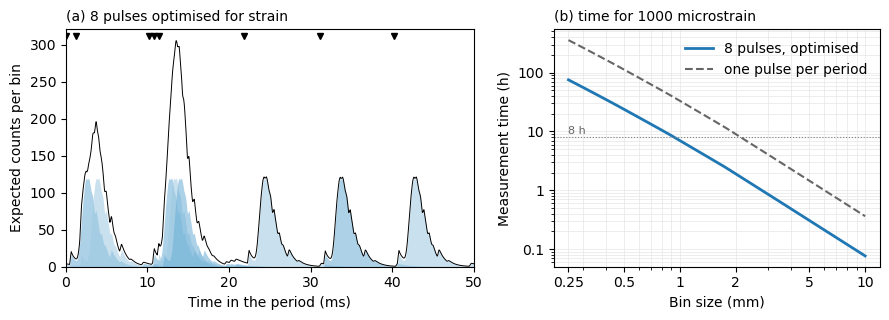

In [4]:
fig = plan.plot(strain=1000)
fig.savefig("../docs/plan_iron.png", dpi=150, bbox_inches="tight")

The plan's model carries the chosen pattern. Other patterns with the same
model: equally spaced pulses put the spectrum of one pulse on the edges of the
next, and random or pseudorandom times gain less than optimised ones.

In [5]:
model = plan.model
patterns = {"4 equal": fo.Pattern.equal(4), "8 equal": fo.Pattern.equal(8),
            "8 random": fo.Pattern.random(8, seed=1), "8 POLDI": fo.Pattern.poldi(),
            "optimised": plan.pattern}
{name: round(model.gain(pattern=p)["strain"], 2) for name, p in patterns.items()}

{'4 equal': 3.24,
 '8 equal': 1.01,
 '8 random': 2.71,
 '8 POLDI': 2.65,
 'optimised': 4.72}

The numbers are Cramér–Rao bounds of the Rietveld fit. They hold when a
spectrum has more than about 5e4 independent counts; check smaller bins with
`plan.monte_carlo(n=100, time=..., bin_size=...)`.